# Gradient Descent $ f{x}^4 $

## **🔸 Imports**

In [13]:
import numpy as np
import matplotlib.pyplot as plt

## **🔸animate Func**

In [14]:
import matplotlib.animation as animation
from IPython.display import HTML

def animate(x, func, gradfunc, xi, eta, N):
    if gradfunc is None:
        gradfunc = func

    xi_hist = [xi]

    for iteration in range(N):
        xi = GradientDescent(gradfunc, xi, eta, 1)
        xi_hist.append(xi)

    xi_hist = np.array(xi_hist)
    fxi_hist = func(xi_hist)

    fig, ax = plt.subplots(figsize=(8, 6))

    def plot_animate(i):
        ax.clear()

        ax.plot(x, func(x), linewidth=3)
        ax.plot(
            xi_hist[:i+1],
            fxi_hist[:i+1],
            color='black',
            linewidth=4
        )
        ax.plot(
            xi_hist[0],
            fxi_hist[0],
            'r*',
            markersize=15
        )

        ax.set_xlabel('x')
        ax.set_ylabel('f(x)')

    ani = animation.FuncAnimation(
        fig,
        plot_animate,
        frames=len(xi_hist),
        interval=120,
        repeat=False
    )

    plt.close(fig)

    return HTML(ani.to_jshtml())


## **🔸Func F(x)**

$ f(x) = 0.125x^4-0.1875x^3-0.75x^2+0.5x $

In [15]:
def funcx4(x):
  return 0.125*x**4 - 0.1875*x**3 - 0.75*x**2 + 0.5*x

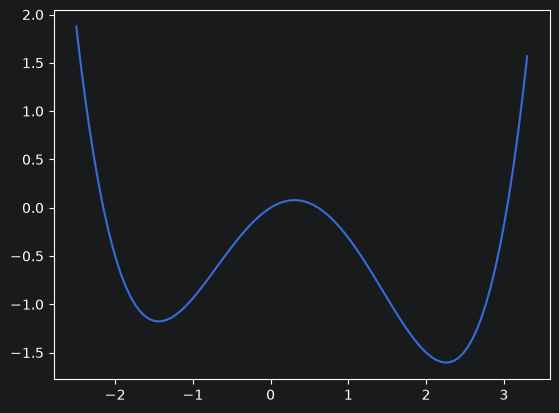

In [16]:
x = np.linspace(-2.5, 3.3, 100)
plt.plot(x, funcx4(x))

## **🔸GradFunc F(x)**

$ f^{'}(x) = 0.5x^3-0.5625x^2-1.5x+0.5$

In [17]:
def gradfx4(x):
  return 0.5*x**3 - 0.5625*x**2 - 1.5*x + 0.5

In [18]:
grad = gradfx4(funcx4(x))

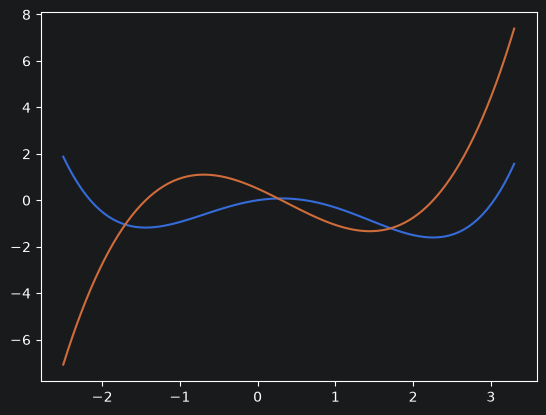

In [19]:
plt.plot(x, funcx4(x))
plt.plot(x, gradfx4(x))

## **🔸Gradient Descent**

### Xi / Learning Rate / Epoch

In [20]:
xi = -3.5
eta = 0.1
epoch = 50

In [25]:
def GradientDescent(gradfunc, xi, eta, N):
    for i in range(N):
        grad = gradfunc(xi)
        xi -= eta*grad
    return xi

In [26]:
GradientDescent(gradfx4, xi, eta, epoch)

-1.4401881808683787

## **🔸Animation Gradient Descent**

In [27]:
animate(x, funcx4, gradfx4, xi=1, eta=0.3, N=10)